### Lab Assignment 2 – HDBSCAN on the Iris Dataset (`sklearn.datasets`)

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler

iris = load_iris()

X = iris.data
y = iris.target

X_scaled = StandardScaler().fit_transform(X)

print(iris.feature_names)
print(X.shape)
print(np.bincount(y))

['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
(150, 4)
[50 50 50]


### HDBSCAN Clustering

In [7]:
from sklearn.cluster import HDBSCAN

hdb = HDBSCAN(min_cluster_size=10)

labels = hdb.fit_predict(X_scaled)

n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise = (labels == -1).sum()
sizes = np.bincount(labels[labels >= 0])

print(f'Number of clusters: {n_clusters}')
print(f'Number of noise points: {n_noise}')
print(f'Cluster sizes: {sizes}')

Number of clusters: 2
Number of noise points: 2
Cluster sizes: [50 98]


d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


In [8]:
for mcs in [5, 10, 15, 20]:
    lab = HDBSCAN(min_cluster_size=mcs).fit_predict(X_scaled)

    print(f'min_cluster_size = {mcs}, clusters: {len(set(lab)) - (1 if -1 in lab else 0)}, noise: {(lab == -1).sum()}')

min_cluster_size = 5, clusters: 2, noise: 2
min_cluster_size = 10, clusters: 2, noise: 2
min_cluster_size = 15, clusters: 2, noise: 4
min_cluster_size = 20, clusters: 2, noise: 6


d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(
d:\anaconda3\Lib\site-packages\sklearn\cluster\_hdbscan\hdbscan.py:722: FutureWarning: The default value of `copy` will change from False to True in 1.10. Explicitly set a value for `copy` to silence this warning.
  warn(


### Visualization with PCA

Explained variance: 0.9581


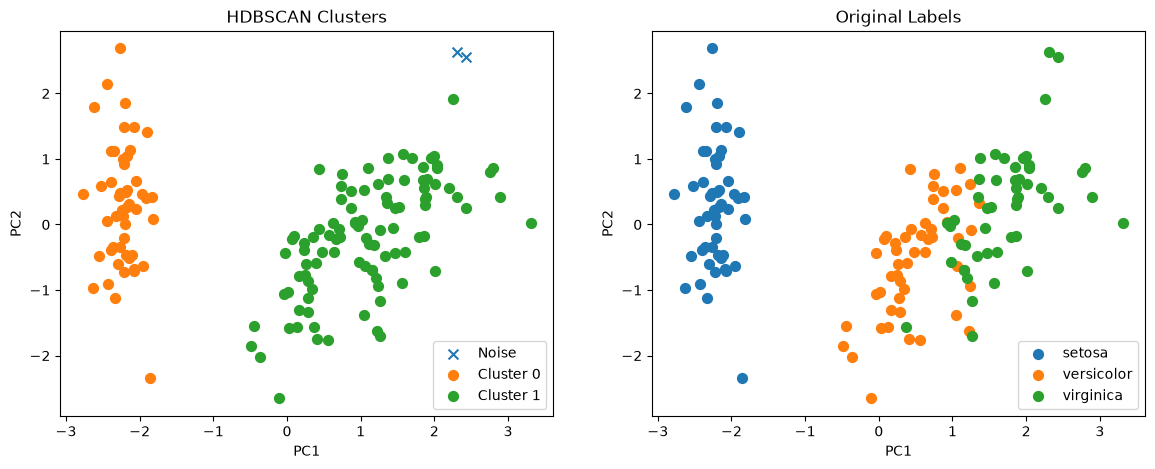

In [9]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_scaled)

print(f'Explained variance: {pca.explained_variance_ratio_.sum():.4f}')

fig, ax = plt.subplots(1, 2, figsize=(14, 5))

for c in np.unique(labels):
    name = 'Noise' if c == -1 else f'Cluster {c}'
    ax[0].scatter(X_pca[labels == c, 0], X_pca[labels == c, 1], s=50, label=name, marker='x' if c == -1 else 'o')

ax[0].set_title('HDBSCAN Clusters')
ax[0].set_xlabel('PC1')
ax[0].set_ylabel('PC2')
ax[0].legend()

for c in np.unique(y):
    ax[1].scatter(X_pca[y == c, 0], X_pca[y == c, 1], s=50, label=iris.target_names[c])

ax[1].set_title('Original Labels')
ax[1].set_xlabel('PC1')
ax[1].set_ylabel('PC2')
ax[1].legend()

plt.show()

**Answer (results):** HDBSCAN found **2 clusters** (sizes 50 and 98) and labeled **2 points as noise**. In the PCA plot, the small cluster is clearly separated from the large one, and the two noise points are outliers far in the upper right corner, away from the dense part of the large cluster (both are *virginica* samples).

### Comparison with the Original Labels

In [10]:
from sklearn.metrics import adjusted_rand_score

ct = pd.crosstab(pd.Series(iris.target_names[y], name='Species'), pd.Series(labels, name='HDBSCAN'))

ari = adjusted_rand_score(y, labels)

print(f'Adjusted Rand Index: {ari:.4f}')

ct

Adjusted Rand Index: 0.5638


HDBSCAN,-1,0,1
Species,,,
setosa,0,50,0
versicolor,0,0,50
virginica,2,0,48


**Answer (analysis):** The result only partly corresponds to the original labels. The dataset has 3 species, but HDBSCAN found 2 clusters. The crosstab shows that one cluster contains exactly the 50 *setosa* samples, which is a perfect match, because setosa is far away from the other two species. The second cluster merges *versicolor* and *virginica*, because these two species overlap in feature space and there is no density gap between them. The adjusted Rand index is 0.564, which reflects this partial agreement. HDBSCAN is a density-based method, so it finds the groups that are separated by low-density regions, not necessarily the three species. Changing `min_cluster_size` between 5 and 20 did not split the merged group, so the result is stable.